# EEG → ERP

## 0. Import i pobranie danych

Wymagane: `mne`, `numpy`, `matplotlib`, `scipy`, `pooch`, `jupyter`. W razie potrzeby uruchom `%pip install -U mne numpy matplotlib scipy pooch` i zrestartuj kernel.

**Metody:** `mne.datasets.eegbci.load_data()`, `mne.io.read_raw_edf()`.

Publiczny plik: PhysioNet EEG Motor Movement/Imagery, uczestnik S001, run 03 (wykonywanie ruchów pięścią po sygnale). Pierwsze pobranie wymaga internetu.

In [3]:
%matplotlib inline
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import mne
import os

print('MNE:', mne.__version__)
new_path = os.path.expanduser("~/mne_data")
os.makedirs(new_path, exist_ok=True)
mne.set_config("MNE_DATA", new_path, set_env=True)
files = mne.datasets.eegbci.load_data(subjects=1, runs=[3], update_path=False)
raw = mne.io.read_raw_edf(files[0], preload=True)
mne.datasets.eegbci.standardize(raw)
print(raw)

MNE: 1.13.2
Extracting EDF parameters from /Users/Emila/mne_data/MNE-eegbci-data/files/eegmmidb/1.0.0/S001/S001R03.edf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 19999  =      0.000 ...   124.994 secs...
<RawEDF | S001R03.edf, 64 x 20000 (125.0 s), ~9.8 MiB, data loaded>


### Sprawdź `Raw` i `Info`

`Raw` przechowuje ciągły sygnał, a `info` metadane. `get_data()` zwraca tablicę w woltach: `(kanały, próbki)`.

In [4]:
print('Kanały:', raw.info['nchan'])
print('Sampling [Hz]:', raw.info['sfreq'])
print('Czas [s]:', raw.times[-1])
print('Bads:', raw.info['bads'])
print('Annotations:', raw.annotations)
print('Macierz (2 kanały × próbki):', raw.get_data(picks=['C3', 'C4'], start=0, stop=1000).shape)

Kanały: 64
Sampling [Hz]: 160.0
Czas [s]: 124.99375
Bads: []
Annotations: <Annotations | 30 segments: T0 (15), T1 (8), T2 (7)>
Macierz (2 kanały × próbki): (2, 1000)


In [5]:
raw.plot()

KeyboardInterrupt: 

Sprawdź: `raw.ch_names`, `raw.info['sfreq']`, `raw.info['bads']`, `raw.annotations`.

In [21]:
ann = raw.annotations

Wywołaj `raw.plot?`. Spróbuj znaleźc informację co robi: `duration`, `start`, `n_channels`, `scalings`.

In [11]:
raw.plot?

Signature:
raw.plot(
    events: numpy.ndarray | None = None,
    duration: float = 10.0,
    start: float = 0.0,
    n_channels: int = 20,
    bgcolor: str | tuple = 'w',
    color: dict | str | tuple | None = None,
    bad_color: str | tuple = 'lightgray',
    event_color: str | tuple | dict | None = 'cyan',
    *,
    annotation_colors: dict | None = None,
    annotation_regex: str = '.*',
    scalings: Literal['auto'] | dict | None = None,
    remove_dc: bool = True,
    order: numpy.ndarray | None = None,
    show_options: bool = False,
    title: str | None = None,
    show: bool = True,
    block: bool = False,
    highpass: float | None = None,
    lowpass: float | None = None,
    filtorder: int = 4,
    clipping: str | float | None = 3,
    show_first_samp: bool = False,
    proj: bool = True,
    group_by: str = 'type',
    butterfly: bool = False,
    decim: int | Literal['auto'] = 'auto',
    noise_cov: 'Covariance | str | None' = None,
    event_id: dict | None = None,
  

## 1. Triggery i zdarzenia

**W Twojej analizie:** `mne.find_events(raw, stim_channel='Status', mask=255, ...)`, kontrola cyklu, porównanie z plikiem `triggerMap`.

**W tym zbiorze:** zdarzenia są zapisane jako anotacje (`T0`, `T1`, `T2`), a nie kanał `Status`. Korzystamy więc z `mne.events_from_annotations()`. To jeden, specyficzny sposób znalezienia struktury `events` (kolumny: numer próbki, poprzednia wartość, kod).

Często używamy również  `mne.find_events()`, ale na to będziemy mieli jeszcze czas przy okazji innych danych :)

In [7]:
print(raw.annotations)
events, event_id = mne.events_from_annotations(raw)

<Annotations | 30 segments: T0 (15), T1 (8), T2 (7)>
Used Annotations descriptions: ['T0', 'T1', 'T2']


In [9]:
print(event_id)
events
#(sample, cos, info jaki id)

{'T0': 1, 'T1': 2, 'T2': 3}


array([[    0,     0,     1],
       [  672,     0,     3],
       [ 1328,     0,     1],
       [ 2000,     0,     2],
       [ 2656,     0,     1],
       [ 3328,     0,     2],
       [ 3984,     0,     1],
       [ 4656,     0,     3],
       [ 5312,     0,     1],
       [ 5984,     0,     3],
       [ 6640,     0,     1],
       [ 7312,     0,     2],
       [ 7968,     0,     1],
       [ 8640,     0,     2],
       [ 9296,     0,     1],
       [ 9968,     0,     3],
       [10624,     0,     1],
       [11296,     0,     2],
       [11952,     0,     1],
       [12624,     0,     3],
       [13280,     0,     1],
       [13952,     0,     3],
       [14608,     0,     1],
       [15280,     0,     2],
       [15936,     0,     1],
       [16608,     0,     2],
       [17264,     0,     1],
       [17936,     0,     3],
       [18592,     0,     1],
       [19264,     0,     2]])

Sprawdźmy: jakie mamy ID, jakie jest 10 pierwszych zdarzeń, co oznacza ich struktura?, jaka jest liczba wszystkich zdarzeń.

Następnie zobaczmy co robi `mne.viz.plot_events` i spróbujmy to wywołać

In [13]:
mne.viz.plot_events?

Signature:
mne.viz.plot_events(
    events,
    sfreq=None,
    first_samp=0,
    color=None,
    event_id=None,
    axes=None,
    equal_spacing=True,
    show=True,
    on_missing='raise',
    verbose=None,
)
Docstring:
Plot :term:`events` to get a visual display of the paradigm.

Parameters
----------

events : ndarray of int, shape (n_events, 3)
    The identity and timing of experimental events, around which the epochs were
    created. See :term:`events` for more information.
sfreq : float | None
    The sample frequency. If None, data will be displayed in samples (not
    seconds).
first_samp : int
    The index of the first sample. Recordings made on Neuromag systems
    number samples relative to the system start (not relative to the
    beginning of the recording). In such cases the ``raw.first_samp``
    attribute can be passed here. Default is 0.
color : dict | None
    Dictionary of event_id integers as keys and colors as values. If None,
    colors are automatically drawn

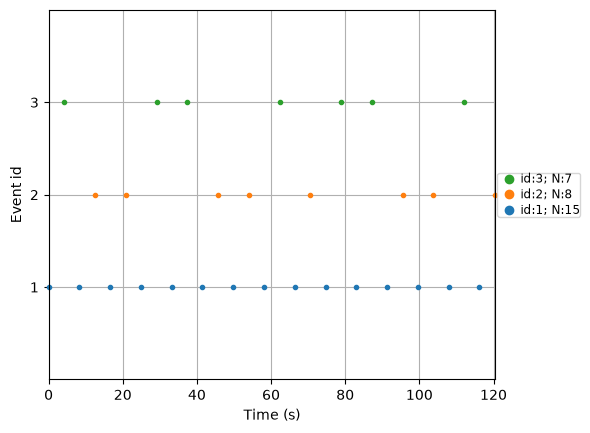

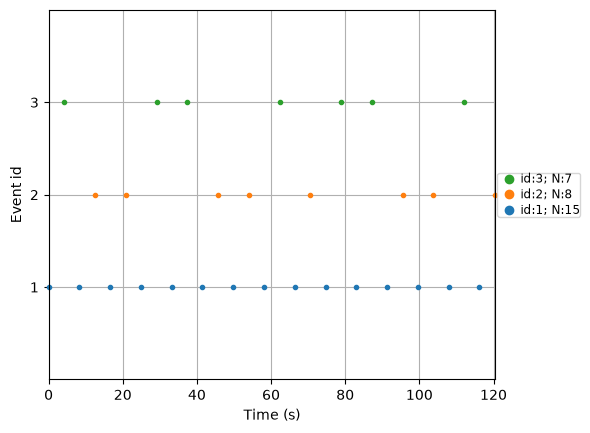

In [14]:
mne.viz.plot_events(events, sfreq=raw.info['sfreq'])

## 2. Resampling 

**Metoda:** `raw.resample(sfreq, events=..., npad='auto')`.

In [15]:
sfreq_before = raw.info['sfreq']

times_before = (events[:, 0] - raw.first_samp) / sfreq_before
raw_rs, events_rs = raw.copy().resample(128, events=events.copy(), npad='auto')
times_after = (events_rs[:, 0] - raw_rs.first_samp) / raw_rs.info['sfreq']

print('Hz:', sfreq_before, '→', raw_rs.info['sfreq'])
print('Próbki:', raw.n_times, '→', raw_rs.n_times)
print('Liczba zdarzeń:', len(events), '→', len(events_rs))
print('Maks. różnica czasu zdarzenia [ms]:', np.max(np.abs(times_after - times_before)) * 1000)

Hz: 160.0 → 128.0
Próbki: 20000 → 16000
Liczba zdarzeń: 30 → 30
Maks. różnica czasu zdarzenia [ms]: 3.1250000000007105


In [17]:
times_before

array([  0. ,   4.2,   8.3,  12.5,  16.6,  20.8,  24.9,  29.1,  33.2,
        37.4,  41.5,  45.7,  49.8,  54. ,  58.1,  62.3,  66.4,  70.6,
        74.7,  78.9,  83. ,  87.2,  91.3,  95.5,  99.6, 103.8, 107.9,
       112.1, 116.2, 120.4])

In [18]:
times_after

array([  0.       ,   4.203125 ,   8.296875 ,  12.5      ,  16.6015625,
        20.796875 ,  24.8984375,  29.1015625,  33.203125 ,  37.3984375,
        41.5      ,  45.703125 ,  49.796875 ,  54.       ,  58.1015625,
        62.296875 ,  66.3984375,  70.6015625,  74.703125 ,  78.8984375,
        83.       ,  87.203125 ,  91.296875 ,  95.5      ,  99.6015625,
       103.796875 , 107.8984375, 112.1015625, 116.203125 , 120.3984375])

W kopii `raw` wykonaj resampling na 100 Hz. Zbadaj `info['sfreq']`, `n_times` i pierwsze indeksy w `events`. Dlaczego próbki się zmieniają, a czasy zdarzeń pozostają zbliżone?

In [19]:
# miejscena rozwiązanie
raw_100 = raw.copy()
events_100 = events.copy()

sfreq_before = raw_100.info['sfreq']

times_before = (events[:, 0] - raw_100.first_samp) / sfreq_before
raw_rs, events_rs = raw_100.copy().resample(128, events=events_100.copy(), npad='auto')
times_after = (events_rs[:, 0] - raw_rs.first_samp) / raw_rs.info['sfreq']

print('Hz:', sfreq_before, '→', raw_rs.info['sfreq'])
print('Próbki:', raw_100.n_times, '→', raw_rs.n_times)
print('Liczba zdarzeń:', len(events_100), '→', len(events_rs))
print('Maks. różnica czasu zdarzenia [ms]:', np.max(np.abs(times_after - times_before)) * 1000)

Hz: 160.0 → 128.0
Próbki: 20000 → 16000
Liczba zdarzeń: 30 → 30
Maks. różnica czasu zdarzenia [ms]: 3.1250000000007105


## 3. Anotacje i montaż

Opisy są już w `raw.annotations`. Dodajemy geometrię (ręcznie, nie na podstawie danych)

Anotacje: <Annotations | 5 segments: T0 (3), T1 (1), T2 (1)>
Montaż przed: None


Montaż po: <DigMontage | 0 extras (headshape), 0 HPIs, 3 fiducials, 64 channels>


/var/folders/rh/p5yby44s3_q7gw0x4t4155p40000gq/T/ipykernel_51762/2831772745.py:4: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  raw_montage = raw_rs.copy().set_montage('standard_1005', match_case=False, on_missing='ignore') # tutaj może być Collins


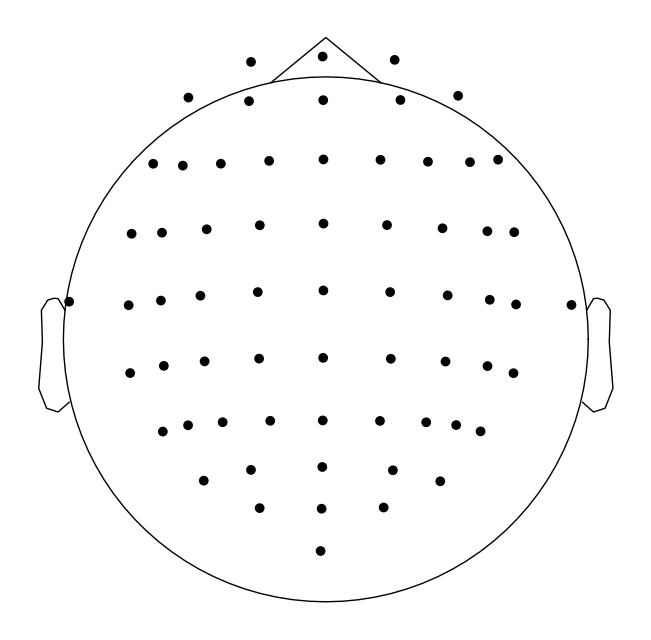

In [20]:
print('Anotacje:', raw_rs.annotations[:5])
print('Montaż przed:', raw_rs.get_montage())

raw_montage = raw_rs.copy().set_montage('standard_1005', match_case=False, on_missing='ignore') # tutaj może być Collins

print('\n\nMontaż po:', raw_montage.get_montage())
raw_montage.plot_sensors(show_names=False, show=False)
plt.show()

**Sprawdź API:** `mne.Annotations?`, `raw.set_annotations?`, `raw.set_montage?`. Jaka jest różnica między `events` (dyskretny moment) i anotacją z niezerowym `duration` (przedział czasu)?

Poniżej utwórz **osobną kopię** i zobacz, jak działa `BAD_...`. 

In [21]:
# Miejsce na rozwiazanie
raw_bad_example = raw.copy()

## 4. Referencja
**Publiczne EEG nie ma kanałów mastoidowych.**

EEG channel type selected for re-referencing
Applying average reference.
Applying a custom ('EEG',) reference.


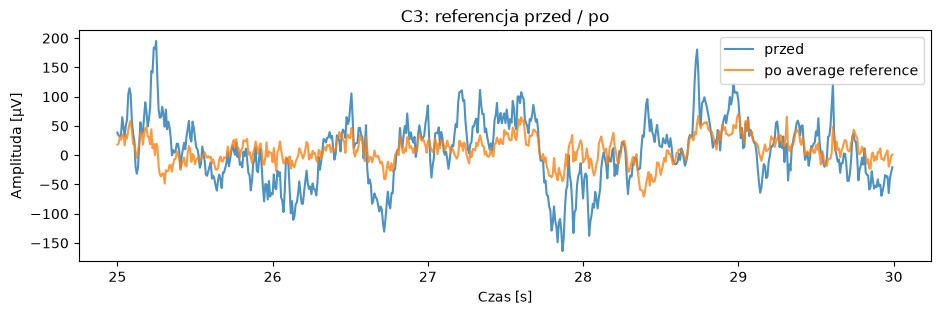

In [22]:
raw_ref = raw_montage.copy().set_eeg_reference(ref_channels='average', projection=False)
fig, ax = plt.subplots(figsize=(11, 3))
ch, t0, t1 = 'C3', 25, 30
for r, label in [(raw_montage, 'przed'), (raw_ref, 'po average reference')]:
    y = r.get_data(picks=[ch], start=int(t0 * r.info['sfreq']), stop=int(t1 * r.info['sfreq']))[0]
    ax.plot(np.arange(y.size) / r.info['sfreq'] + t0, y * 1e6, label=label, alpha=.8)
ax.set(xlabel='Czas [s]', ylabel='Amplituda [µV]', title=f'{ch}: referencja przed / po')
ax.legend(); plt.show()

**Sprawdź parametry:** `raw.set_eeg_reference?` — `ref_channels`, `projection`, `ch_type`. Dlaczego ważne jest `.copy()`? Uruchom wariant z `ref_channels=['Cz']` na **tej samej kopii wejściowej**, a nie na `raw_ref`.

Object `set_eeg_reference` not found.


In [ ]:
# Tworzymy wspólną kopię wejściową
raw_before_ref = raw.copy()

# Referencja do średniej
raw_ref = raw.copy().set_eeg_reference(ref_channels='average', projection=True)

# Referencja do Cz – z tego samego sygnału wejściowego
raw_ref_cz = raw.copy().set_eeg_reference(ref_channels=['Cz'], projection=False)

EEG channel type selected for re-referencing
Adding average EEG reference projection.
1 projection items deactivated
Average reference projection was added, but has not been applied yet. Use the apply_proj method to apply it.
EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.


In [ ]:
# Porównanie sygnału przy trzech referencjach
raw_before_ref.plot(
    start=10,
    duration=5,
    n_channels=10,
    title="Oryginalna referencja"
)

#raw_ref.plot(
#    start=10,
#    duration=5,
#    n_channels=10,
#    title="Average reference"
#)

#raw_ref_cz.plot(
#    start=10,
#    duration=5,
#    n_channels=10,
#    title="Referencja Cz"
#)

## 5. Filtrowanie

In [ ]:
raw_hp = raw_ref.copy().filter(l_freq=0.05, h_freq=None, picks='eeg', method='iir', iir_params=dict(ftype='butter', order=2), phase='zero')
raw_lp = raw_hp.copy().filter(l_freq=None, h_freq=25.0, picks='eeg', method='iir', iir_params=dict(ftype='butter', order=1), phase='zero')
print(raw_hp)
print(raw_lp)

### Co stało się z sygnałem w czasie?

In [ ]:
fig, ax = plt.subplots(figsize=(12, 3))
for r, label in [(raw_ref, 'przed'), (raw_hp, 'po HP'), (raw_lp, 'po HP + LP')]:
    y = r.get_data(picks=['C3'], start=2500, stop=3500)[0]
    x = np.arange(len(y)) / r.info['sfreq'] + 2500 / r.info['sfreq']
    ax.plot(x, y * 1e6, label=label, alpha=.8)
ax.set(xlabel='Czas [s]', ylabel='C3 [µV]'); ax.legend(); plt.show()

### Co stało się z widmem?

`raw.compute_psd()` to metoda MNE do oszacowania widma mocy. Wykresy przed i po pokazujemy w tej samej skali.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3), sharey=True)
raw_ref.compute_psd(picks=['C3'], fmax=60).plot(axes=axes[0], show=False)
raw_lp.compute_psd(picks=['C3'], fmax=60).plot(axes=axes[1], show=False)
axes[0].set_title('Przed filtracją'); axes[1].set_title('Po HP + LP')
plt.show()

**Sprawdź:** `raw.filter?`, `raw.notch_filter?`. Wykonaj filtr notch w *osobnej* kopii. Najpierw spójrz na PSD w okolicy 50 Hz; porównaj wynik przed i po.

In [ ]:
# miejsce na rozwiazanie

## 6. Epoki wokół wskazówek ruchowych

In [ ]:
conditions = {'lewa': event_id['T1'], 'prawa': event_id['T2']}
epochs = mne.Epochs(
    raw_lp, events_rs, event_id=conditions,
    tmin=-0.25, tmax=0.95, baseline=[-.1,0],
    preload=True, reject_by_annotation=True)
print(epochs)
print('Kształt:', epochs.get_data().shape)
print('Czas pierwszych próbek:', epochs.times[:5])
print('Drop log:', epochs.drop_log[:5])

**Sprawdź metodę:** `mne.Epochs?` — `event_id`, `tmin`, `tmax`, `baseline`, `preload`, `reject_by_annotation`. Porównaj `len(epochs)` i `epochs['lewa']`, obejrzyj przebiegi za pomocą `epochs.plot()` i pojedyncze epoki przez `epochs.get_data()`.

In [ ]:
# Miejsce na rozwiazanie

## 7. Kontrola artefaktów i odrzucanie danych
 `epochs.drop_bad(reject={'eeg': ...})`. **Uwaga:** `reject` jest progiem *peak-to-peak* (max−min) w epoce; odrzuca całą epokę, nie tylko kanał.

In [ ]:
amplitudes = np.ptp(epochs.get_data(picks='eeg'), axis=-1) * 1e6
peak_per_epoch = amplitudes.max(axis=1)
plt.figure(figsize=(9, 3))
plt.hist(peak_per_epoch, bins=25)
plt.axvline(150, color='red', label='Przykładowy próg 150 µV p–p')
plt.xlabel('Największe peak-to-peak w epoce [µV]')
plt.ylabel('Liczba epok'); plt.legend(); plt.show()
print('Liczba epok przed:', len(epochs))

In [ ]:
epochs_clean = epochs.copy().drop_bad(reject=dict(eeg=900e-6))
print('Liczba epok po:', len(epochs_clean))
print('Lewy warunek:', len(epochs_clean['lewa']))
print('Prawy warunek:', len(epochs_clean['prawa']))
epochs_clean.plot_drop_log(show=False)
plt.show()

**Sprawdź argumenty:** `epochs.drop_bad?`: `reject`, `flat`, `reject_tmin`, `reject_tmax`. Porównaj liczbę prób po progach 100 i 200 µV p–p.

In [ ]:
# miejsce na rozwiazanie

## 8. Od epok do uśrednionej odpowiedzi (`Evoked`)

`Evoked` przechowuje średni przebieg oraz `nave`, czyli liczbę uśrednianych epok. 

In [ ]:
evoked_left = epochs_clean['lewa'].average()
evoked_right = epochs_clean['prawa'].average()
print('Średnia — lewa:', evoked_left, 'nave:', evoked_left.nave)
print('Średnia — prawa:', evoked_right, 'nave:', evoked_right.nave)
mne.viz.plot_compare_evokeds({'lewa': evoked_left, 'prawa': evoked_right},
                             picks=['C3', 'C4'], combine='mean', show=False)
plt.show()

### Mapy topograficzne i zmiany wywołane preprocessingiem

In [ ]:
evoked_left = epochs["lewa"].average()
evoked_right = epochs["prawa"].average()

print("Lewa — nave:", evoked_left.nave)
print("Prawa — nave:", evoked_right.nave)

In [ ]:
# Te same momenty czasowe i wspólna skala kolorów
times = [0.0, 0.2, 0.4, 0.6, 0.8]

# Wspólna skala dla obu warunków (w µV)
vlim = (-10, 10)

evoked_left.plot_topomap(
    times=times,
    ch_type="eeg",
    vlim=vlim,
    colorbar=True,
    time_unit="s",
)

evoked_right.plot_topomap(
    times=times,
    ch_type="eeg",
    vlim=vlim,
    colorbar=True,
    time_unit="s",
)

print("Lewa/Prawa")

In [ ]:
evoked_diff = mne.combine_evoked(
    [evoked_left, evoked_right],
    weights=[1, -1]
)

evoked_diff.plot_topomap(
    times=times,
    ch_type="eeg",
    vlim=vlim,
    colorbar=True,
    time_unit="s",
)
print("Roznicowa")